### juvenile_ESN

Contains the very first working implementation of an Echo State Network \
Tested against the Logistic Map toy system \
--- Date:    March 2026

In [5]:
import numpy as np
import matplotlib.pyplot as plt

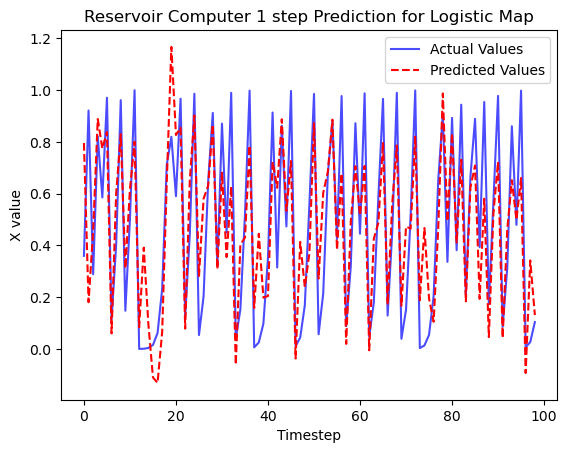

In [6]:

np.random.seed(123)

def logistic_map(r,x0,iterations):
    # r: parameter value
    #x0: starting value
    #iterations: number of vals 

    x=np.zeros(iterations)
    x[0] = x0

    for k in range(iterations-1):
        
        x[k+1] = r * x[k] * (1-x[k])
    return x


# p = spectral radius
p = 1
N = 10 # number of nodes 

# creating the weight matrix - identity matrix of 10x10
Vadj = np.eye(N) * p 
# multiply by spectral radius to control stability and memory (??)

#creating random input weights (10x1)
Vin = np.random.uniform(-1,1,size=(N,1))

#creating bias vector (10x number of obs)
Vbias = np.random.uniform(-1,1,size=(N,))

example = logistic_map(4,0.1,100)

#initial reservoir state 
x = np.zeros(N)

#reservoir states
states = np.zeros((len(example), N))

for i in range(len(example)):
    x = np.tanh(np.matmul(Vadj, x) + np.matmul(Vin,[example[i]]) + Vbias)
    states[i] = x

X = states[:-1] #input to use for prediction
Y = example[1:] #target 'next' value of the prediction

least_squares = np.linalg.lstsq(X,Y, rcond=None)
#lstsq will return solution, residuals, rank, singular_vals
Vout = least_squares[0]

Y_predicted = np.matmul(X, Vout)

plt.plot(Y, label = 'Actual Values',color='blue', alpha=0.7)
plt.plot(Y_predicted, label='Predicted Values',color='red', linestyle='dashed')
plt.xlabel('Timestep')
plt.ylabel('X value')
plt.legend()
plt.title('Reservoir Computer 1 step Prediction for Logistic Map')
plt.savefig('FirstOutput.png')